# 00 – Patient Selection
Downloads the numerics files of all ICU stays in the MIMIC-IV Waveform Database v0.1.0, checks their quality and selects those for our project (see D4 and D5 in `decisions.md`).

## 1. Setup
Load the libraries and define where the data is online (BASE) and where it is locally (DATA_DIR)

In [1]:
import os
import urllib.request
import pandas as pd
import seaborn as sns

BASE = "https://physionet.org/files/mimic4wdb/0.1.0/"
DATA_DIR = os.path.join("..", "dataset", "mimic4wdb")
os.makedirs(DATA_DIR, exist_ok=True)

## 2. List of patients
Read the dataset's main RECORDS file: official list of all 198 patients

In [3]:
patients = pd.read_csv(BASE + "RECORDS", header=None, names=["path"])["path"].tolist()
print(len(patients), "patients")
print(patients[:3])

198 patients
['waves/p100/p10014354/', 'waves/p100/p10019003/', 'waves/p100/p10020306/']


## 3. Link each patient to their ICU stay(s) 
Each patient folder has its own RECORDS file with the stay(s) number(s). We need the stay number because the data file is named after the stay and not the patient. 
Larger pauses prevent server errors (502) and retries handle temporary server errors (502).

In [4]:
import time

def fetch_text(url, tries=5):
    for attempt in range(1, tries + 1):
        try:
            return urllib.request.urlopen(url, timeout=30).read().decode()
        except Exception as e:
            print(f"  attempt {attempt} failed ({e}), waiting {5 * attempt} s...")
            time.sleep(5 * attempt)
    raise RuntimeError(f"Gave up on {url}")

records = []
for i, p in enumerate(patients, start=1):
    text = fetch_text(BASE + p + "RECORDS")
    for line in text.split():
        records.append(p + line)
    time.sleep(0.2)
    if i % 20 == 0:
        print(f"{i}/{len(patients)} patients checked")

print(len(records), "records")
print(records[:3])

20/198 patients checked
40/198 patients checked
60/198 patients checked
80/198 patients checked
100/198 patients checked
120/198 patients checked
140/198 patients checked
160/198 patients checked
  attempt 1 failed (<urlopen error [WinError 10060] A connection attempt failed because the connected party did not properly respond after a period of time, or established connection failed because connected host has failed to respond>), waiting 5 s...
180/198 patients checked
200 records
['waves/p100/p10014354/81739927/81739927', 'waves/p100/p10019003/87033314/87033314', 'waves/p100/p10020306/83404654/83404654']


## 4. Download the numerics files
We download only the **numerics** (`<stay>n.csv.gz`): the vital signs the monitor derives from the waveforms. They match our question (deterioration over minutes to hours) and are much smaller (stay 83404654: 7.2 MB vs. ~143 MB of waveforms). Decisions can be seen in D1 of 'decisions.md'.

The download is resumable (existing files are skipped), safe (`.part` until complete), retries server errors (502), and records stays without numerics (404), which are excluded.

In [7]:
import urllib.error

REDOWNLOAD = False   # change to True to download EVERYTHING again

def download(url, target, tries=5):
    for attempt in range(1, tries + 1):
        try:
            urllib.request.urlretrieve(url, target + ".part")
            os.replace(target + ".part", target)
            return "ok"
        except urllib.error.HTTPError as e:
            if e.code == 404:
                return "missing"
            print(f"  attempt {attempt} failed ({e}), waiting {5 * attempt} s...")
            time.sleep(5 * attempt)
        except Exception as e:
            print(f"  attempt {attempt} failed ({e}), waiting {5 * attempt} s...")
            time.sleep(5 * attempt)
    return "failed"

skipped, downloaded, missing, failed = [], [], [], []

for i, rec in enumerate(records, start=1):
    parts = rec.split("/")
    patient, record_id = parts[2], parts[-1]
    filename = f"{patient}_{record_id}n.csv.gz"
    target = os.path.join(DATA_DIR, filename)

    if os.path.exists(target) and not REDOWNLOAD:
        skipped.append(rec)
    else:
        result = download(BASE + rec + "n.csv.gz", target)
        if result == "ok":
            downloaded.append(rec)
        elif result == "missing":
            missing.append(rec)
        else:
            failed.append(rec)
        time.sleep(0.2)

    if i % 20 == 0:
        print(f"{i}/{len(records)} records checked")

print()
print(len(skipped), "already there (skipped)")
print(len(downloaded), "newly downloaded")
print(len(missing), "have no numerics file (404)")
print(len(failed), "failed:", failed)

20/200 records checked
40/200 records checked
60/200 records checked
80/200 records checked
100/200 records checked
120/200 records checked
  attempt 1 failed (HTTP Error 502: Bad Gateway), waiting 5 s...
140/200 records checked
160/200 records checked
180/200 records checked
200/200 records checked

56 already there (skipped)
138 newly downloaded
6 have no numerics file (404)
0 failed: []


## 5. Check the download
Count the downloaded numerics files and their total size, as a check.
**Result:** 194 files, 579 MB in total.
- 200 ICU stays in the dataset; 6 have no numerics file (404) and are excluded, leaving 194.
- The numerics are ~4.5% of the full dataset (579 MB vs. 12.8 GB, which is mostly waveforms)

In [5]:
files = [f for f in os.listdir(DATA_DIR) if f.endswith("n.csv.gz")]
total_mb = sum(os.path.getsize(os.path.join(DATA_DIR, f)) for f in files) / 1e6
print(len(files), "files,", round(total_mb), "MB in total")

194 files, 579 MB in total


## 6. Look inside a numerics file
Example: patient p10020306, stay 83404654.

**Findings:**
- **Size:** 756,823 rows and 21 columns: `time` plus 20 monitor values (e.g. blood pressure from a cuff and from an arterial line, several heart/pulse rates, ECG details such as QT and ST).
- **Our 5 vital signs:** heart rate `HR [bpm]`, respiratory rate `RR [rpm]`, oxygen saturation `SpO2 [%]`, systolic and diastolic cuff blood pressure `NBPs [mmHg]` and `NBPd [mmHg]` (see D2 and D3).
- **Mostly empty cells:** each row is a moment where the monitor wrote down a new value for at least one signal. The other columns in that row are empty (`NaN` = "no new value at this moment", not zero).
- **Time:** `time` counts in ticks (999.56 per second) and can be slightly negative. Rows are roughly 1 second apart.
- **Shuffled rows:** the rows are not in time order (e.g. 0 → −4549 → 672). See "Data conventions" in `decisions.md` for how we handle time and sorting.

In [6]:
example = os.path.join(DATA_DIR, "p10020306_83404654n.csv.gz")
df = pd.read_csv(example)

print(df.shape)
print(list(df.columns))
df.head()

(756823, 21)
['time', 'ABPd [mmHg]', 'ABPm [mmHg]', 'ABPs [mmHg]', 'DeltaQTc [msec]', 'HR [bpm]', 'NBPd [mmHg]', 'NBPm [mmHg]', 'NBPs [mmHg]', 'PVC [/min]', 'Pulse (ABP) [bpm]', 'Pulse (NBP) [bpm]', 'Pulse (SpO2) [bpm]', 'QT [msec]', 'QT-HR [bpm]', 'QTc [msec]', 'RR [rpm]', 'ST-III [mm]', 'ST-V [mm]', 'SpO2 [%]', 'btbHR [bpm]']


,time,ABPd [mmHg],ABPm [mmHg],ABPs [mmHg],DeltaQTc [msec],HR [bpm],NBPd [mmHg],NBPm [mmHg],NBPs [mmHg],PVC [/min],...,Pulse (NBP) [bpm],Pulse (SpO2) [bpm],QT [msec],QT-HR [bpm],QTc [msec],RR [rpm],ST-III [mm],ST-V [mm],SpO2 [%],btbHR [bpm]
0,0,NaN,NaN,NaN,NaN,NaN,77.0,91.0,122.0,NaN,...,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,-4549,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,86.64
2,672,NaN,NaN,NaN,NaN,107.0,NaN,NaN,NaN,1.0,...,NaN,NaN,NaN,NaN,NaN,19.0,NaN,NaN,NaN,NaN
3,1696,NaN,NaN,NaN,NaN,107.0,NaN,NaN,NaN,1.0,...,NaN,NaN,NaN,NaN,NaN,20.0,NaN,NaN,NaN,NaN
4,2720,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,21.0,NaN,NaN,NaN,NaN


## 7. How often is each vital sign measured? (one patient)
For patient p10020306 (stay 83404654), we count the measurements of our 5 vital signs, the typical (median) gap between them, and the longest gap.

**Result:**
- HR, RR and SpO2 are measured about **every second** (~265,000 values each); their longest gap is ~24 minutes.
- The cuff blood pressure (NBPs/NBPd) has only ~370 values, and a **25.8-hour gap** without any cuff measurement.
- NBPd has fewer values than NBPs (353 vs. 385): some cuff readings have no diastolic value.

The cuff is the limiting signal, and a long stay is not automatically a complete one. This is why we need a coverage criterion (**section 8**).

In [7]:
signals = ["HR [bpm]", "RR [rpm]", "SpO2 [%]", "NBPs [mmHg]", "NBPd [mmHg]"]

rows = []
for s in signals:
    t = df.loc[df[s].notna(), "time"].sort_values()
    gaps_s = t.diff() / 999.56
    rows.append({
        "signal": s,
        "measurements": len(t),
        "median gap (s)": round(gaps_s.median(), 1),
        "longest gap (h)": round(gaps_s.max() / 3600, 1),
    })

pd.DataFrame(rows)

,signal,measurements,median gap (s),longest gap (h)
0,HR [bpm],266438,1.0,0.4
1,RR [rpm],264753,1.0,0.4
2,SpO2 [%],264797,1.0,0.4
3,NBPs [mmHg],385,97.3,25.8
4,NBPd [mmHg],353,112.7,25.8


### 7.1 Zoom in: the cuff blood pressure (NBP)

**Result:** mean gap 11.9 min, median 1.6 min, max 1548 min (25.8 h).
- The mean is pulled up by the one 26-hour gap (an outlier), so it is misleading.
- A median of 1.6 min (and a minimum of 5 s) is too short for a real cuff. **Confirmed in section 9:** ~85% of the cuff rows are copies of the previous value.

In [8]:
nbp = df[["time", "NBPs [mmHg]"]].dropna().sort_values("time")
gaps_min = nbp["time"].diff() / 999.56 / 60
print(len(nbp), "cuff measurements")
print(gaps_min.describe())

385 cuff measurements
count     384.000000
mean       11.915910
std       112.314560
min         0.085371
25%         0.597596
50%         1.622047
75%         3.500207
max      1548.457321
Name: time, dtype: float64


## 8. Duration and coverage of all 194 stays
For each stay we calculate its duration (hours) and, for each of our 5 vital signs (HR, RR, SpO2, NBPs, NBPd), its **coverage**: the percentage of hours that contain at least one measurement. It doesn't matter whether an hour as 1 or 3600 measurements, we only check whether the hour has data at all.

`min_coverage` is the **lowest** of these 5 coverages. A stay passes a coverage rule only if **every one of the 5 signals** meets it, because our models need all 5 signals together; the weakest signal decides. In practice this is almost always the cuff blood pressure (NBP).

Example: p10020306 has 100% for HR, RR and SpO2 but 23.4% for NBP → min_coverage = 23.4%.

### 8.1 A function that summarizes one stay

In [9]:
signals = ["HR [bpm]", "RR [rpm]", "SpO2 [%]", "NBPs [mmHg]", "NBPd [mmHg]"]
TICKS_PER_SECOND = 999.56

def stay_summary(path):
    df_s = pd.read_csv(path, usecols=lambda c: c == "time" or c in signals)
    hours = (df_s["time"] - df_s["time"].min()) / TICKS_PER_SECOND / 3600
    hour_block = hours.astype(int)
    n_blocks = hour_block.max() + 1

    row = {
        "file": os.path.basename(path),
        "patient": os.path.basename(path).split("_")[0],
        "duration_h": round(hours.max(), 1),
    }
    for s in signals:
        if s in df_s.columns:
            covered = hour_block[df_s[s].notna()].nunique()
        else:
            covered = 0
        row[s] = round(100 * covered / n_blocks, 1)
    row["min_coverage"] = min(row[s] for s in signals)
    return row

### 8.2 Apply it to all 194 stays
The result is one table with a row per stay, saved as `dataset/coverage_summary.csv`.

In [10]:
files = sorted(f for f in os.listdir(DATA_DIR) if f.endswith("n.csv.gz"))

summary = []
for i, f in enumerate(files, start=1):
    summary.append(stay_summary(os.path.join(DATA_DIR, f)))
    if i % 20 == 0:
        print(f"{i}/{len(files)} stays checked")

coverage = pd.DataFrame(summary)
coverage.to_csv(os.path.join("..", "dataset", "coverage_summary.csv"), index=False)
print(len(coverage), "stays summarized")
coverage.describe()

20/194 stays checked
40/194 stays checked
60/194 stays checked
80/194 stays checked
100/194 stays checked
120/194 stays checked
140/194 stays checked
160/194 stays checked
180/194 stays checked
194 stays summarized


,duration_h,HR [bpm],RR [rpm],SpO2 [%],NBPs [mmHg],NBPd [mmHg],min_coverage
count,194.000000,194.000000,194.000000,194.000000,194.000000,194.000000,194.000000
mean,46.285567,96.806186,96.900000,95.741753,74.335567,74.335567,70.266495
std,54.684289,16.131929,14.632447,14.829698,34.905967,34.905967,35.915972
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,12.825000,100.000000,100.000000,100.000000,43.125000,43.125000,37.975000
50%,29.400000,100.000000,100.000000,100.000000,98.350000,98.350000,92.850000
75%,61.225000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000
max,342.200000,100.000000,100.000000,100.000000,100.000000,100.000000,100.000000


### 8.3 Sanity check
We test the code on p10020306, the patient we studied in section 7. We expect ~76 h, ~100% for HR/RR/SpO2 and low cuff coverage (the 26-hour gap).

In [11]:
coverage[coverage["patient"] == "p10020306"]

,file,patient,duration_h,HR [bpm],RR [rpm],SpO2 [%],NBPs [mmHg],NBPd [mmHg],min_coverage
2,p10020306_83404654n.csv.gz,p10020306,76.3,100.0,100.0,100.0,23.4,23.4,23.4


**Result:** 76.3 h, HR/RR/SpO2 100%, but cuff (NBP) only **23.4%** → the code works, and this stay is long but very incomplete.

**All 194 stays:** median duration 29.4 h (25%: 12.8 h, max 342 h). HR, RR and SpO2 have ~100% coverage in most stays; the cuff has a median of 98%, but a quarter of the stays have < 43%.

### 8.4 Visual check: when is each signal measured?
For p10020306 we plot one dot per measurement, per signal, over time. Gaps show up as empty stretches. We also count how many rows are out of time order.

9 of 756823 rows come earlier in time than the row before them


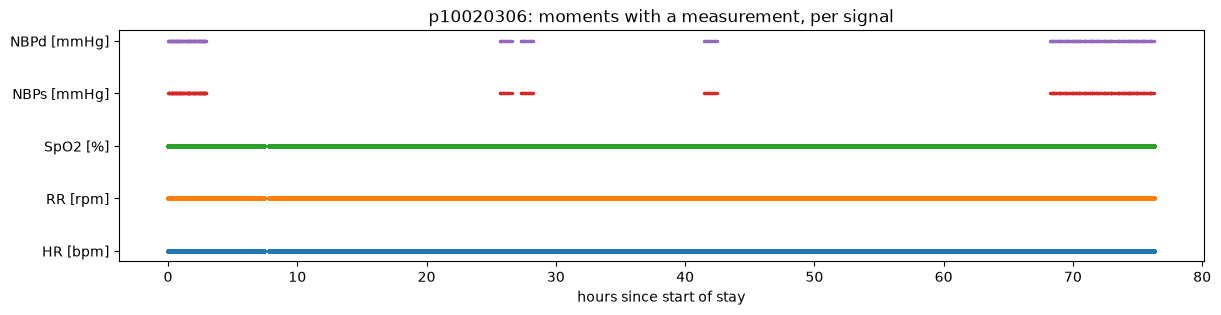

In [19]:
d = pd.read_csv(os.path.join(DATA_DIR, "p10020306_83404654n.csv.gz"),
                usecols=lambda c: c == "time" or c in signals)

out_of_order = (d["time"].diff() < 0).sum()
print(out_of_order, "of", len(d), "rows come earlier in time than the row before them")

d = d.sort_values("time")
hours = (d["time"] - d["time"].min()) / TICKS_PER_SECOND / 3600

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(14, 3))
for i, s in enumerate(signals):
    t = hours[d[s].notna()]
    ax.scatter(t, [i] * len(t), s=2)
ax.set_yticks(range(len(signals)))
ax.set_yticklabels(signals)
ax.set_xlabel("hours since start of stay")
ax.set_title("p10020306: moments with a measurement, per signal")
plt.show()

### 8.5 How many stays pass different selection rules?
Combinations of a minimum duration (12 or 24 h) and a minimum `min_coverage` (70, 80 or 90%).

In [12]:
for min_hours in [12, 24]:
    for min_cov in [70, 80, 90]:
        ok = (coverage["duration_h"] >= min_hours) & (coverage["min_coverage"] >= min_cov)
        print(f"duration >= {min_hours:>2} h and min_coverage >= {min_cov}%: "
              f"{ok.sum():>3} stays, {coverage.loc[ok, 'patient'].nunique():>3} patients")

duration >= 12 h and min_coverage >= 70%:  97 stays,  97 patients
duration >= 12 h and min_coverage >= 80%:  89 stays,  89 patients
duration >= 12 h and min_coverage >= 90%:  81 stays,  81 patients
duration >= 24 h and min_coverage >= 70%:  75 stays,  75 patients
duration >= 24 h and min_coverage >= 80%:  70 stays,  70 patients
duration >= 24 h and min_coverage >= 90%:  63 stays,  63 patients


**How many stays pass?** Even the strictest combination (≥ 24 h, ≥ 90%) leaves 63 stays (63 patients); the loosest (≥ 12 h, ≥ 70%) leaves 97. Every option exceeds the 30 we planned, so using all eligible stays is possible (see D5). These numbers may be slightly optimistic: cuff copies (section 9) also count as coverage. Section 10 recomputes coverage with real measurements only and applies the final rule (D4).

### 8.6 Curiosity check: very short stays

In [13]:
print((coverage["duration_h"] < 1).sum(), "stays shorter than 1 hour")

8 stays shorter than 1 hour


## 9. How often does the cuff really measure? (input for D7)
The cuff (NBP) is our sparsest signal, so it limits how fine our time grid can be. The monitor re-writes the last displayed cuff value every ~2 minutes, even without a new measurement. We therefore count a cuff row as a **real** measurement only if (NBPs, NBPd, NBPm) differs from the previous cuff row. We use the candidate stays (≥ 12 h, min_coverage ≥ 70%).

### 9.1 A function that finds the real cuff measurements

In [14]:
candidates = coverage[(coverage["duration_h"] >= 12) & (coverage["min_coverage"] >= 70)]
NBP_COLS = ["NBPs [mmHg]", "NBPd [mmHg]", "NBPm [mmHg]"]

def new_cuff_minutes(d):
    """Minutes since start of each REAL new cuff measurement (copies removed)."""
    minutes = (d["time"] - d["time"].min()) / TICKS_PER_SECOND / 60
    cuff = d.assign(m=minutes).dropna(subset=["NBPs [mmHg]"]).sort_values("time")
    vals = cuff[[c for c in NBP_COLS if c in cuff.columns]].fillna(-1)
    changed = vals.ne(vals.shift()).any(axis=1)
    return minutes, cuff.loc[changed, "m"]

print(len(candidates), "candidate stays")

97 candidate stays


### 9.2 How many cuff values are copies?

In [15]:
rep = []
for f in candidates["file"]:
    d = pd.read_csv(os.path.join(DATA_DIR, f), usecols=lambda c: c == "time" or c in NBP_COLS)
    minutes, new_minutes = new_cuff_minutes(d)
    cuff_rows = d["NBPs [mmHg]"].notna().sum()
    rep.append({
        "file": f,
        "cuff_rows": cuff_rows,
        "new_values": len(new_minutes),
        "repeats (%)": 100 * (1 - len(new_minutes) / cuff_rows),
        "new_per_hour": len(new_minutes) / (minutes.max() / 60),
    })

repeats = pd.DataFrame(rep)
repeats.describe().round(1)

,cuff_rows,new_values,repeats (%),new_per_hour
count,97.0,97.0,97.0,97.0
mean,1206.6,212.7,83.7,3.7
std,1135.4,244.0,6.4,2.1
min,119.0,9.0,63.9,0.7
25%,486.0,62.0,80.0,2.0
50%,935.0,143.0,85.2,2.9
75%,1422.0,243.0,89.2,4.6
max,6302.0,1289.0,92.4,12.2


**Result (97 stays):** ~85% of cuff rows are copies. Real new cuff measurements occur ~2.9 times per hour (median), i.e. about **every 20 minutes** (25%: every ~30 min, 75%: every ~13 min).
Limitation: two real measurements with exactly the same values count as one (rare).

### 9.3 Which grid size?
For different grid sizes, the percentage of time blocks that contain at least one **real** cuff measurement (copies removed).

In [16]:
grids = [5, 10, 15, 30, 60]

results = []
for f in candidates["file"]:
    d = pd.read_csv(os.path.join(DATA_DIR, f), usecols=lambda c: c == "time" or c in NBP_COLS)
    minutes, new_minutes = new_cuff_minutes(d)
    row = {"file": f}
    for g in grids:
        n_blocks = int(minutes.max() // g) + 1
        row[f"filled_{g}min (%)"] = 100 * (new_minutes // g).nunique() / n_blocks
    results.append(row)

grid_check = pd.DataFrame(results)
grid_check.describe().round(1)

,filled_5min (%),filled_10min (%),filled_15min (%),filled_30min (%),filled_60min (%)
count,97.0,97.0,97.0,97.0,97.0
mean,16.4,30.8,43.5,66.1,92.3
std,9.1,16.5,21.2,19.4,9.8
min,5.3,10.5,13.7,23.1,46.2
25%,9.1,18.1,26.7,50.3,89.5
50%,13.1,24.8,37.7,62.0,96.2
75%,19.6,38.2,55.3,80.7,99.3
max,50.6,100.0,100.0,100.0,100.0


**Result (97 stays, real measurements only, median):** 15-min grid → 38% of blocks contain a real cuff measurement; 30 min → 62%; 60 min → 96%. The cuff is much sparser than the copied values suggested. To discuss for D7.

## 10. Real NBP coverage without repeated copies and arterial line (ABP) bias (Verifying D4)

The bedside ICU monitor re-writes the last non-invasive cuff measurement every ~2 minutes until a new inflation occurs (~80%–85% of NBP rows are identical repeats).
Here we recalculate coverage per hour considering **only real measurements** (where NBP values genuinely change).

Furthermore, we compare **included vs. excluded stays** under the proposed filter (`duration_h >= 12` and `min_coverage >= 80%`) to test for **clinical selection bias**: do excluded patients have continuous invasive arterial lines (`ABPs/d/m`)?

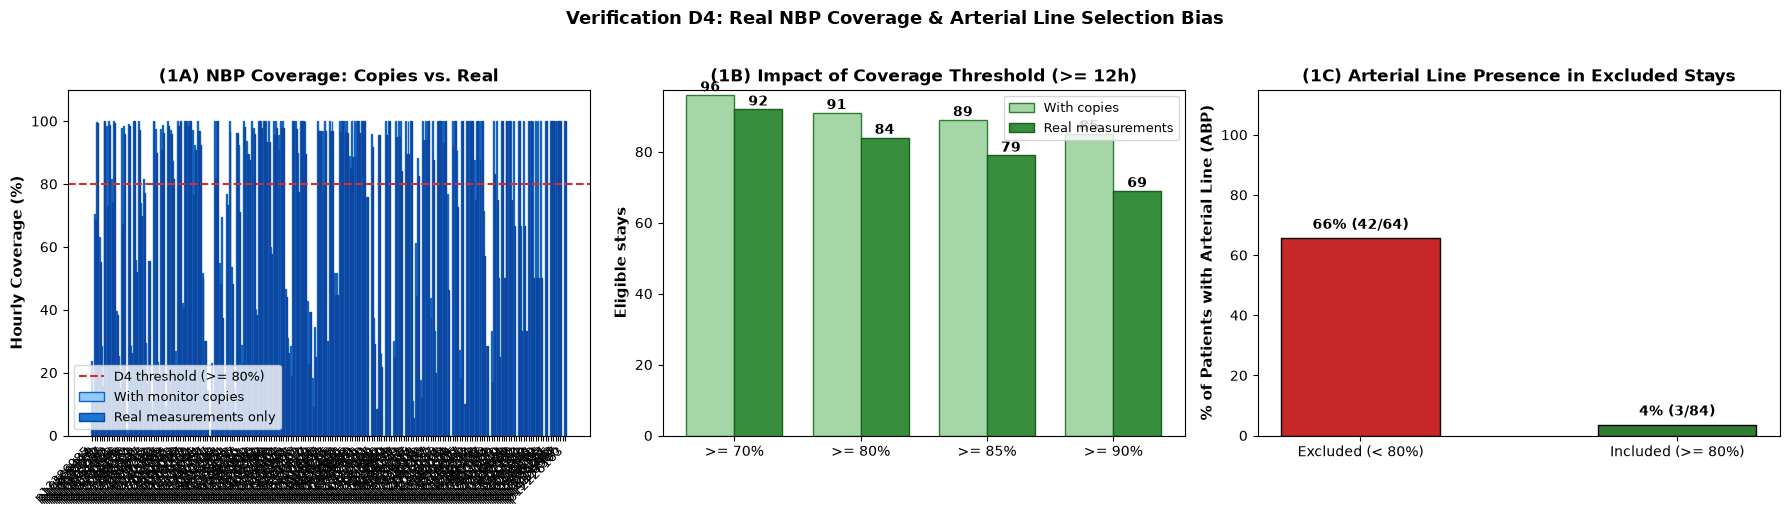

Summary Table (Real vs. Copies):
  patient  duration_h  cov_with_copies  cov_real  repeats_pct  has_abp  abp_rows
p10014354   29.608619            100.0      96.7         79.5    False         0
p10019003   67.815268            100.0      98.5         81.0    False         0
p10020306   76.304237             23.4      18.2         76.6     True    217472
p10039708   16.808371             88.2      82.4         83.1    False         0
p10039708    2.876016            100.0      66.7         90.9    False         0
p10079700   59.715989            100.0     100.0         83.2    False         0
p10082591    1.576231            100.0      50.0         94.7    False         0
p10100546  137.143520             25.4      15.2         92.3    False         0
p10112163   75.968199             97.4      90.8         84.7    False         0
p10126957   23.736809             37.5      29.2         81.1     True     76587
p10209410   28.114170             51.7      44.8         88.4     True     6

In [16]:
import os, gzip
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = os.path.join("..", "dataset", "mimic4wdb")
if not os.path.exists(DATA_DIR):
    DATA_DIR = os.path.join("dataset", "mimic4wdb")

files = sorted(f for f in os.listdir(DATA_DIR) if f.endswith("n.csv.gz"))
TICKS_PER_SECOND = 999.56
NBP_COLS = ["NBPs [mmHg]", "NBPd [mmHg]"]
ABP_COLS = ["ABPs [mmHg]", "ABPd [mmHg]"]
CORE_SIGNALS = ["HR [bpm]", "RR [rpm]", "SpO2 [%]", "NBPs [mmHg]", "NBPd [mmHg]"]

patient_rows = []
for f in files:
    fpath = os.path.join(DATA_DIR, f)
    cols = pd.read_csv(fpath, nrows=1).columns.tolist()
    use_cols = [c for c in cols if c == "time" or c in CORE_SIGNALS or c in ABP_COLS]
    df = pd.read_csv(fpath, usecols=use_cols)
    
    dur_h = (df["time"].max() - df["time"].min()) / TICKS_PER_SECOND / 3600
    hour_blocks = ((df["time"] - df["time"].min()) / TICKS_PER_SECOND / 3600).astype(int)
    n_blocks = hour_blocks.max() + 1
    
    has_nbp = "NBPs [mmHg]" in df.columns and df["NBPs [mmHg]"].notna().sum() > 0
    cuff_rows = df["NBPs [mmHg]"].notna().sum() if has_nbp else 0
    has_abp = "ABPs [mmHg]" in df.columns and df["ABPs [mmHg]"].notna().sum() > 0
    abp_rows = df["ABPs [mmHg]"].notna().sum() if has_abp else 0
    
    cov_with_copies = round(100 * hour_blocks[df["NBPs [mmHg]"].notna()].nunique() / n_blocks, 1) if has_nbp else 0.0
    
    if has_nbp:
        cuff = df.dropna(subset=["NBPs [mmHg]"]).sort_values("time")
        vals = cuff[[c for c in NBP_COLS if c in cuff.columns]].fillna(-1)
        changed = vals.ne(vals.shift()).any(axis=1)
        real_cuff = cuff.loc[changed]
        n_real = len(real_cuff)
        real_hour_blocks = ((real_cuff["time"] - df["time"].min()) / TICKS_PER_SECOND / 3600).astype(int)
        cov_real = round(100 * real_hour_blocks.nunique() / n_blocks, 1)
    else:
        n_real = 0
        cov_real = 0.0
        
    patient_rows.append({
        "patient": f.split("_")[0],
        "duration_h": dur_h,
        "cov_with_copies": cov_with_copies,
        "cov_real": cov_real,
        "cuff_rows": cuff_rows,
        "n_real": n_real,
        "repeats_pct": round(100 * (1 - n_real / cuff_rows), 1) if cuff_rows > 0 else 0,
        "has_abp": has_abp,
        "abp_rows": abp_rows
    })

p_df = pd.DataFrame(patient_rows)

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
p_df_sorted = p_df.sort_values("duration_h", ascending=False).reset_index(drop=True)
x = np.arange(len(p_df_sorted))
width = 0.38

# Panel 1A: With copies vs Real
axes[0].bar(x - width/2, p_df_sorted["cov_with_copies"], width, label="With monitor copies", color="#90CAF9", edgecolor="#1565C0")
axes[0].bar(x + width/2, p_df_sorted["cov_real"], width, label="Real measurements only", color="#1976D2", edgecolor="#0D47A1")
axes[0].axhline(80, color="#D32F2F", linestyle="--", linewidth=1.5, label="D4 threshold (>= 80%)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(p_df_sorted["patient"], rotation=45, ha='right', fontsize=9)
axes[0].set_ylabel("Hourly Coverage (%)", fontsize=11, fontweight='bold')
axes[0].set_title("(1A) NBP Coverage: Copies vs. Real", fontsize=12, fontweight='bold')
axes[0].legend(loc="lower left", fontsize=9)
axes[0].set_ylim(0, 110)

# Panel 1B: Sensitivity of stays passing D4
thresholds = [70, 80, 85, 90]
pass_copies = [((p_df["duration_h"] >= 12) & (p_df["cov_with_copies"] >= t)).sum() for t in thresholds]
pass_real = [((p_df["duration_h"] >= 12) & (p_df["cov_real"] >= t)).sum() for t in thresholds]
x_t = np.arange(len(thresholds))
axes[1].bar(x_t - width/2, pass_copies, width, label="With copies", color="#A5D6A7", edgecolor="#2E7D32")
axes[1].bar(x_t + width/2, pass_real, width, label="Real measurements", color="#388E3C", edgecolor="#1B5E20")
for i in range(len(thresholds)):
    axes[1].text(x_t[i] - width/2, pass_copies[i] + 0.1, str(pass_copies[i]), ha='center', va='bottom', fontweight='bold')
    axes[1].text(x_t[i] + width/2, pass_real[i] + 0.1, str(pass_real[i]), ha='center', va='bottom', fontweight='bold')
axes[1].set_xticks(x_t)
axes[1].set_xticklabels([f">= {t}%" for t in thresholds])
axes[1].set_ylabel("Eligible stays", fontsize=11, fontweight='bold')
axes[1].set_title("(1B) Impact of Coverage Threshold (>= 12h)", fontsize=12, fontweight='bold')
axes[1].legend(loc="upper right", fontsize=9)
axes[1].set_ylim(0, max(pass_copies) + 1.5)

# Panel 1C: Clinical Selection Bias
d12_pts = p_df[p_df["duration_h"] >= 12.0].copy()
d12_pts["group"] = np.where(d12_pts["cov_real"] >= 80.0, "Included (>= 80%)", "Excluded (< 80%)")
bias_agg = d12_pts.groupby("group").agg(
    total=("patient", "count"),
    with_abp=("has_abp", "sum"),
    abp_pct=("has_abp", lambda s: 100 * s.mean())
).reset_index()

colors_bias = ["#2E7D32" if "Included" in g else "#C62828" for g in bias_agg["group"]]
bars = axes[2].bar(bias_agg["group"], bias_agg["abp_pct"], color=colors_bias, width=0.5, edgecolor="black")
for bar, total, count in zip(bars, bias_agg["total"], bias_agg["with_abp"]):
    yval = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width()/2, yval + 2, f"{yval:.0f}% ({count}/{total})", ha='center', va='bottom', fontweight='bold', fontsize=10)
axes[2].set_ylabel("% of Patients with Arterial Line (ABP)", fontsize=11, fontweight='bold')
axes[2].set_title("(1C) Arterial Line Presence in Excluded Stays", fontsize=12, fontweight='bold')
axes[2].set_ylim(0, 115)

plt.suptitle("Verification D4: Real NBP Coverage & Arterial Line Selection Bias", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("Summary Table (Real vs. Copies):")
display_cols = ["patient", "duration_h", "cov_with_copies", "cov_real", "repeats_pct", "has_abp", "abp_rows"]
print(p_df[display_cols].to_string(index=False))


In [ ]:
passes = (p_df["duration_h"] >= 12) & (p_df["cov_real"] >= 80)
included = p_df[passes]
excluded = p_df[~passes]
excluded_long = excluded[excluded["duration_h"] >= 12]

print(len(p_df), "stays checked")
print(len(included), "stays pass the rule (D4)")
print(len(excluded), "stays are excluded,", len(excluded_long), "of them are at least 12 h long")
print(excluded_long["has_abp"].sum(), "of those", len(excluded_long), "have an arterial line")

**Findings and Clinical Bias Interpretation (D4):**
1. **Without copies/cuff coverage stability**, cuff coverage barely changes for stays where the cuff is used regularly (e.g. p10014354: 100% → 96.7%; p10019003: 100% → 98.5%).
2. **84 of the 194 stays pass the rule.** 110 are excluded: 46 because they are shorter than 12 h, 64 only because of low cuff coverage.
3. **Of those 64, 42 (two thirds) have an arterial line** (e.g. p10020306 with 217,000 ABP values). In clinical practice, nurses rarely inflate the arm cuff when blood pressure is already monitored continuously through an arterial line. Our inclusion criteria therefore, in practice, focus on non-invasively monitored ICU patients and probably under-represents the sickest patients (see D4). Not all excluded stays have one: e.g. p10100546 (137 h) has no arterial line.

1A: Cobertura con copias vs. lecturas reales por paciente.
1B: Sensibilidad de pacientes que superan el filtro según el umbral.
1C: Comprobación del sesgo clínico: de las 64 estancias largas excluidas por baja cobertura del manguito, 42 (dos tercios) tienen línea arterial invasiva (ABPs/d/m). No todas: p. ej. p10100546 no tiene.
Interpretación clínica: Documentación del límite del estudio para la defensa oral del examen.

## 11. Distribution of NBP sampling intervals and gaps (Verifying D7)

To understand how sparse non-invasive blood pressure is in real ICU practice, we extract every time interval between genuine cuff inflations and analyze their distribution.

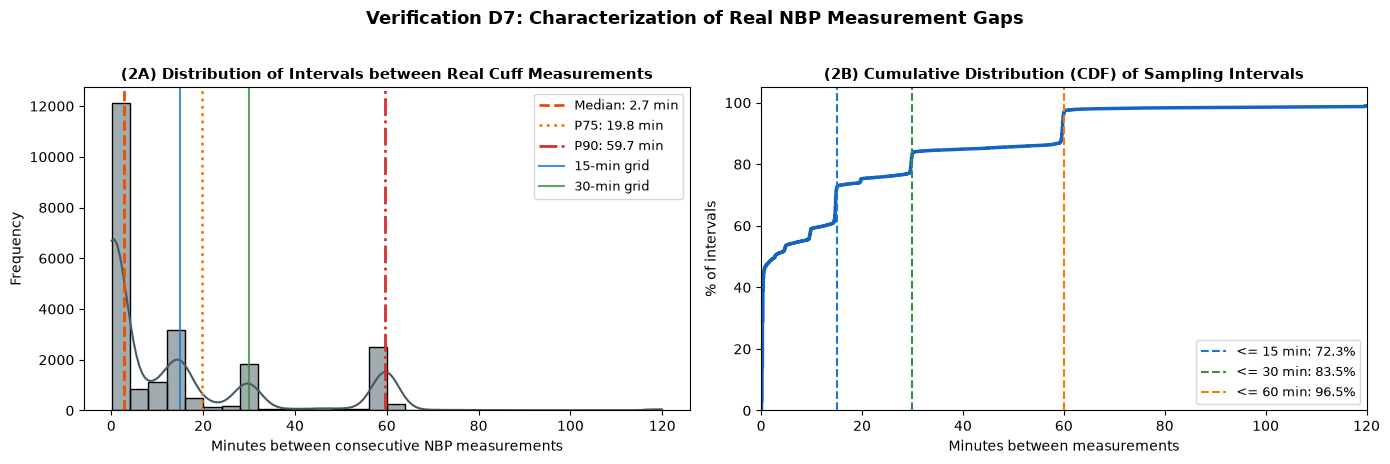

Sampling Gap Statistics: Median = 2.7 min | P75 = 19.8 min | P90 = 59.7 min
Percentage of gaps <= 30 min: 83.5% | <= 60 min: 96.5%


In [13]:
all_gaps_min = []
for f in files:
    fpath = os.path.join(DATA_DIR, f)
    cols = pd.read_csv(fpath, nrows=1).columns.tolist()
    if "NBPs [mmHg]" not in cols:
        continue
    df = pd.read_csv(fpath, usecols=["time", "NBPs [mmHg]", "NBPd [mmHg]"])
    cuff = df.dropna(subset=["NBPs [mmHg]"]).sort_values("time")
    vals = cuff[["NBPs [mmHg]", "NBPd [mmHg]"]].fillna(-1)
    changed = vals.ne(vals.shift()).any(axis=1)
    real_cuff = cuff.loc[changed]
    real_m = real_cuff["time"] / TICKS_PER_SECOND / 60
    gaps = real_m.diff().dropna().values
    all_gaps_min.extend(gaps[gaps > 0])

all_gaps = np.array(all_gaps_min)
med = np.median(all_gaps)
p75 = np.percentile(all_gaps, 75)
p90 = np.percentile(all_gaps, 90)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Panel 2A: Histogram of intervals <= 120 min
normal_gaps = all_gaps[all_gaps <= 120]
sns.histplot(normal_gaps, bins=30, kde=True, color="#455A64", edgecolor="black", ax=axes[0])
axes[0].axvline(med, color="#E65100", linestyle="--", linewidth=2, label=f"Median: {med:.1f} min")
axes[0].axvline(p75, color="#F57C00", linestyle=":", linewidth=2, label=f"P75: {p75:.1f} min")
axes[0].axvline(p90, color="#D32F2F", linestyle="-.", linewidth=2, label=f"P90: {p90:.1f} min")
axes[0].axvline(15, color="#1976D2", linestyle="-", linewidth=1.5, alpha=0.8, label="15-min grid")
axes[0].axvline(30, color="#388E3C", linestyle="-", linewidth=1.5, alpha=0.8, label="30-min grid")
axes[0].set_title("(2A) Distribution of Intervals between Real Cuff Measurements", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Minutes between consecutive NBP measurements", fontsize=10)
axes[0].set_ylabel("Frequency", fontsize=10)
axes[0].legend(fontsize=9)

# Panel 2B: CDF
sorted_gaps = np.sort(all_gaps)
cdf = np.arange(1, len(sorted_gaps) + 1) / len(sorted_gaps)
axes[1].plot(sorted_gaps, cdf * 100, color="#1565C0", linewidth=2.5)
axes[1].axvline(15, color="#1976D2", linestyle="--", label=f"<= 15 min: {100*np.mean(all_gaps <= 15):.1f}%")
axes[1].axvline(30, color="#388E3C", linestyle="--", label=f"<= 30 min: {100*np.mean(all_gaps <= 30):.1f}%")
axes[1].axvline(60, color="#F57C00", linestyle="--", label=f"<= 60 min: {100*np.mean(all_gaps <= 60):.1f}%")
axes[1].set_xlim(0, 120)
axes[1].set_ylim(0, 105)
axes[1].set_title("(2B) Cumulative Distribution (CDF) of Sampling Intervals", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Minutes between measurements", fontsize=10)
axes[1].set_ylabel("% of intervals", fontsize=10)
axes[1].legend(loc="lower right", fontsize=9)

plt.suptitle("Verification D7: Characterization of Real NBP Measurement Gaps", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print(f"Sampling Gap Statistics: Median = {med:.1f} min | P75 = {p75:.1f} min | P90 = {p90:.1f} min")
print(f"Percentage of gaps <= 30 min: {100*np.mean(all_gaps <= 30):.1f}% | <= 60 min: {100*np.mean(all_gaps <= 60):.1f}%")


**Result (all stays with a cuff, real measurements only):** median gap 2.7 min, P75 19.8 min, P90 59.7 min; 72% of gaps are ≤ 15 min, 84% ≤ 30 min, 97% ≤ 60 min. The histogram shows peaks at ~2–3, ~15, ~30 and ~60 minutes.

2A: Histograma de los intervalos entre mediciones reales del manguito, con la mediana (2.7 min), P75 (19.8 min), P90 (59.7 min) y las grillas de 15 y 30 min. Se ven picos en ~15, ~30 y ~60 min (temporizadores del manguito).
2B: Curva de distribución acumulada (CDF): el 72% de los intervalos es ≤ 15 min, el 84% ≤ 30 min y el 97% ≤ 60 min.

### 11.1 Comparison: included vs. excluded stays
Do the 84 included stays have different cuff gaps than the excluded stays? If the excluded stays have more long gaps, this confirms from another angle that our rule removes stays with sparse cuff use (see section 10 and D4).

,all stays,included,excluded
gaps,23605.0,17533.0,6072.0
median (min),2.7,2.7,2.8
P75 (min),19.8,15.5,29.9
P90 (min),59.7,59.5,59.8
<= 15 min (%),72.3,74.1,67.0
<= 30 min (%),83.5,86.0,76.3
<= 60 min (%),96.5,98.0,92.1
> 2 h (%),1.0,0.2,3.5


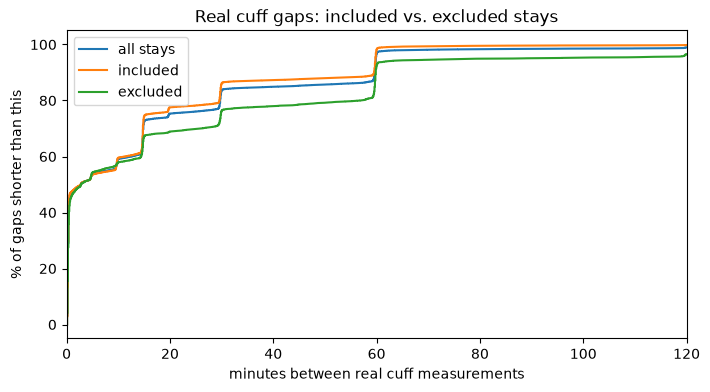

In [19]:
use_patients = set(included["patient"])

gaps = {"included": [], "excluded": []}
for f in files:
    fpath = os.path.join(DATA_DIR, f)
    d = pd.read_csv(fpath, usecols=lambda c: c in ["time", "NBPs [mmHg]", "NBPd [mmHg]"])
    if "NBPs [mmHg]" not in d.columns:
        continue
    cuff = d.dropna(subset=["NBPs [mmHg]"]).sort_values("time")
    vals = cuff.drop(columns="time").fillna(-1)
    real = cuff[vals.ne(vals.shift()).any(axis=1)]
    g = (real["time"].diff() / TICKS_PER_SECOND / 60).dropna()
    group = "included" if f.split("_")[0] in use_patients else "excluded"
    gaps[group].extend(g[g > 0])

gaps["all stays"] = gaps["included"] + gaps["excluded"]

def summarize(x):
    x = np.array(x)
    return {
        "gaps": len(x),
        "median (min)": round(np.median(x), 1),
        "P75 (min)": round(np.percentile(x, 75), 1),
        "P90 (min)": round(np.percentile(x, 90), 1),
        "<= 15 min (%)": round(100 * (x <= 15).mean(), 1),
        "<= 30 min (%)": round(100 * (x <= 30).mean(), 1),
        "<= 60 min (%)": round(100 * (x <= 60).mean(), 1),
        "> 2 h (%)": round(100 * (x > 120).mean(), 1),
    }

comparison = pd.DataFrame({k: summarize(gaps[k]) for k in ["all stays", "included", "excluded"]})
display(comparison)

fig, ax = plt.subplots(figsize=(8, 4))
for k in ["all stays", "included", "excluded"]:
    x = np.sort(gaps[k])
    ax.plot(x, 100 * np.arange(1, len(x) + 1) / len(x), label=k)
ax.set_xlim(0, 120)
ax.set_xlabel("minutes between real cuff measurements")
ax.set_ylabel("% of gaps shorter than this")
ax.set_title("Real cuff gaps: included vs. excluded stays")
ax.legend()
plt.show()

**Result:** both groups have the same median gap (~2.7 min), but the excluded stays have clearly more long gaps: P75 29.9 vs. 15.5 min, and gaps longer than 2 hours are ~17× more common (3.5% vs. 0.2%).

### Conclusion of section 11
1. **The cuff works on timers.** The peaks at 15, 30 and 60 minutes suggest the cuff is set to measure automatically at one of these intervals, chosen per patient. The very short gaps (~2–3 min) are extra measurements in quick succession.
2. **Short gaps are common, but most time passes in long gaps.** Each burst creates several short gaps, so the median is low (2.7 min), while most of the time lies in the timer intervals. This is why only ~38% of 15-minute blocks contain a real cuff value (section 9.3).
3. **Our rule removes the stays with long cuff pauses.** Excluded stays have about 17× more gaps longer than 2 hours. This confirms the selection bias from section 10 from another angle (D4).
4. **For our 84 included stays, 74% of the gaps are ≤ 15 minutes**, which supports the 15-minute grid (D7). The remaining gaps are filled in (section 12).

## 12. Filling the gaps with a Gaussian Process: 15 vs. 30 minutes (D7)
**Question:** can we fill the empty blood-pressure blocks reliably, and is a 15- or 30-minute grid better?

- We test this on one patient: p10019003 (one of our 84 included stays), first 20 hours, real systolic cuff values only. 
- A Gaussian Process (GP) with a Matérn kernel (ν = 1.5) and 
- Noise term (WhiteKernel) estimates every block, with a 95% band (μ ± 1.96σ). 
- To measure how good the estimates are, we hide real values, let the GP guess them and compute the error (CV-RMSE).

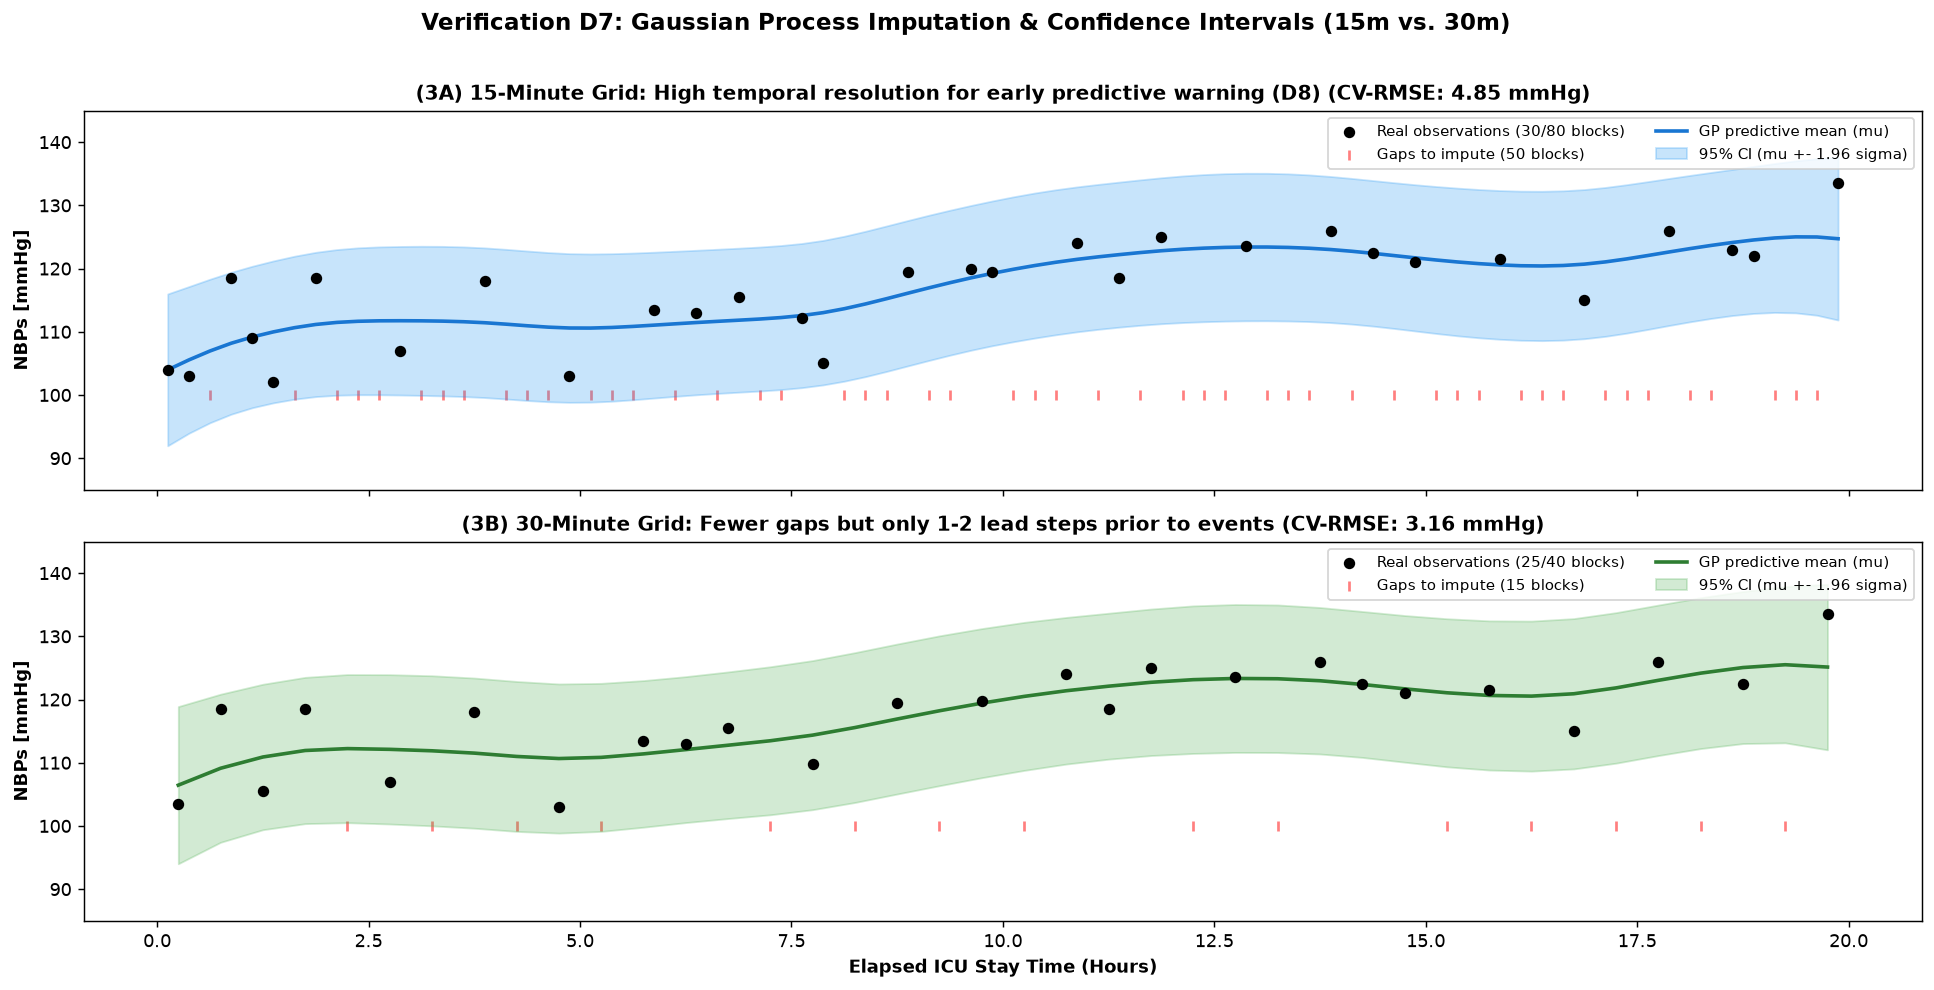

15-min grid: 80 blocks, 30 observed (37.5%), CV-RMSE = 4.85 mmHg, Lead steps in 60m = 4 steps
30-min grid: 40 blocks, 25 observed (62.5%), CV-RMSE = 3.16 mmHg, Lead steps in 60m = 2 steps


In [ ]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel as C, WhiteKernel, Matern

# Load patient p10019003
f_rep = os.path.join(DATA_DIR, "p10019003_87033314n.csv.gz")
df_rep = pd.read_csv(f_rep, usecols=["time", "NBPs [mmHg]", "NBPd [mmHg]"])
cuff_rep = df_rep.dropna(subset=["NBPs [mmHg]"]).sort_values("time")
vals_rep = cuff_rep[["NBPs [mmHg]", "NBPd [mmHg]"]].fillna(-1)
changed_rep = vals_rep.ne(vals_rep.shift()).any(axis=1)
real_rep = cuff_rep.loc[changed_rep].copy()
real_rep["hours"] = (real_rep["time"] - df_rep["time"].min()) / TICKS_PER_SECOND / 3600
real_rep = real_rep[real_rep["hours"] <= 20.0].copy()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 7.5), sharex=True)

def fit_and_plot_gp(ax, grid_min, title_str, color_line, color_fill):
    bins = np.arange(0, 20.0 + grid_min/60.0, grid_min/60.0)
    real_rep["bin"] = np.digitize(real_rep["hours"], bins) - 1
    agg = real_rep.groupby("bin")["NBPs [mmHg]"].mean().reset_index()
    
    grid_centers = (bins[:-1] + bins[1:]) / 2
    grid_df = pd.DataFrame({"bin": range(len(bins)-1), "t_h": grid_centers})
    merged = pd.merge(grid_df, agg, on="bin", how="left")
    
    obs = merged.dropna(subset=["NBPs [mmHg]"])
    X_train = obs["t_h"].values.reshape(-1, 1)
    y_train = obs["NBPs [mmHg]"].values
    X_all = merged["t_h"].values.reshape(-1, 1)
    
    kernel = C(50.0, (1.0, 500.0)) * Matern(length_scale=2.5, length_scale_bounds=(0.8, 8.0), nu=1.5) + WhiteKernel(noise_level=16.0, noise_level_bounds=(1.0, 64.0))
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=3, random_state=42)
    gp.fit(X_train, y_train)
    y_pred, y_std = gp.predict(X_all, return_std=True)
    
    # 20% validation split RMSE
    np.random.seed(42)
    n_obs = len(obs)
    val_idx = np.random.choice(n_obs, size=max(1, int(0.2 * n_obs)), replace=False)
    t_mask = np.ones(n_obs, dtype=bool)
    t_mask[val_idx] = False
    gp_val = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=2, random_state=42)
    gp_val.fit(X_train[t_mask], y_train[t_mask])
    pred_val = gp_val.predict(X_train[val_idx])
    rmse = np.sqrt(np.mean((pred_val - y_train[val_idx])**2))
    
    ax.scatter(obs["t_h"], obs["NBPs [mmHg]"], color="black", s=28, zorder=4, label=f"Real observations ({len(obs)}/{len(merged)} blocks)")
    missing = merged[merged["NBPs [mmHg]"].isna()]
    ax.scatter(missing["t_h"], [100]*len(missing), marker="|", color="red", s=35, alpha=0.5, label=f"Gaps to impute ({len(missing)} blocks)")
    
    ax.plot(merged["t_h"], y_pred, color=color_line, linewidth=2, label="GP predictive mean (mu)")
    ax.fill_between(merged["t_h"], y_pred - 1.96 * y_std, y_pred + 1.96 * y_std, color=color_fill, alpha=0.25, label="95% CI (mu +- 1.96 sigma)")
    
    ax.set_ylabel("NBPs [mmHg]", fontsize=10, fontweight='bold')
    ax.set_title(f"{title_str} (CV-RMSE: {rmse:.2f} mmHg)", fontsize=11, fontweight='bold')
    ax.legend(loc="upper right", fontsize=8.5, ncol=2)
    ax.set_ylim(85, 145)
    return len(merged), len(obs), rmse

n_15, obs_15, rmse_15 = fit_and_plot_gp(ax1, 15, "(3A) 15-Minute Grid: High temporal resolution for early predictive warning (D8)", "#1976D2", "#2196F3")
n_30, obs_30, rmse_30 = fit_and_plot_gp(ax2, 30, "(3B) 30-Minute Grid: Fewer gaps but only 1-2 lead steps prior to events", "#2E7D32", "#4CAF50")

ax2.set_xlabel("Elapsed ICU Stay Time (Hours)", fontsize=10, fontweight='bold')
plt.suptitle("Verification D7: Gaussian Process Imputation & Confidence Intervals (15m vs. 30m)", fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

print(f"15-min grid: {n_15} blocks, {obs_15} observed ({100*obs_15/n_15:.1f}%), CV-RMSE = {rmse_15:.2f} mmHg, Lead steps in 60m = 4 steps")
print(f"30-min grid: {n_30} blocks, {obs_30} observed ({100*obs_30/n_30:.1f}%), CV-RMSE = {rmse_30:.2f} mmHg, Lead steps in 60m = 2 steps")


**Result (p10019003, first 20 h):**
| Grid | Blocks | Blocks with a real measurement | Blocks to guess | Error (CV-RMSE) | Points per hour |
|---|---|---|---|---|---|
| 15 min | 80 | 30 | 50 | 4.85 mmHg | 4 |
| 30 min | 40 | 25 | 15 | 3.16 mmHg | 2 |

**Conclusion (D7):**
- Filling the gaps works on both grids: the GP is off by only a few mmHg.
- 30 minutes guesses a bit better (fewer blocks to guess). 15 minutes gives twice as many moments per hour to notice that something goes wrong.
- Our goal is early warning, so we choose **15 minutes**. The slightly larger error is the price.
- The GP draws a smooth line and ignores single low values (e.g. ~103 mmHg around hour 5). A real dip could be missed, so we keep the real measurements next to the filled values (notebook 02).
- Limitation: one patient, 20 hours. It shows that filling *can* work, not that it works equally well for all 84 stays.

- **Expected trade-off for alarms:** more points per hour should help to detect deterioration earlier (fewer missed events, false negatives), but more filled-in values may also cause more false alarms (false positives). Because a missed deterioration is usually worse than a false alarm in the ICU, we accept this risk; the actual balance will be tested with the cost model in notebook XX.

### 12.1 What if the GP treats (almost) nothing as noise?
In 12, the GP learned a high noise level from the data, so its line is smooth and does not follow single low values. Here we compare it with a GP forced to assume almost no noise (its line must pass near every measurement), on the same patient and 15-minute grid. CV-RMSE shows which one predicts hidden measurements better.

noise learned    CV-RMSE = 5.96 mmHg | learned kernel: 1.01**2 * Matern(length_scale=13.7, nu=1.5) + WhiteKernel(noise_level=0.459)
almost no noise  CV-RMSE = 7.44 mmHg | learned kernel: 0.98**2 * Matern(length_scale=0.404, nu=1.5) + WhiteKernel(noise_level=0.0001)


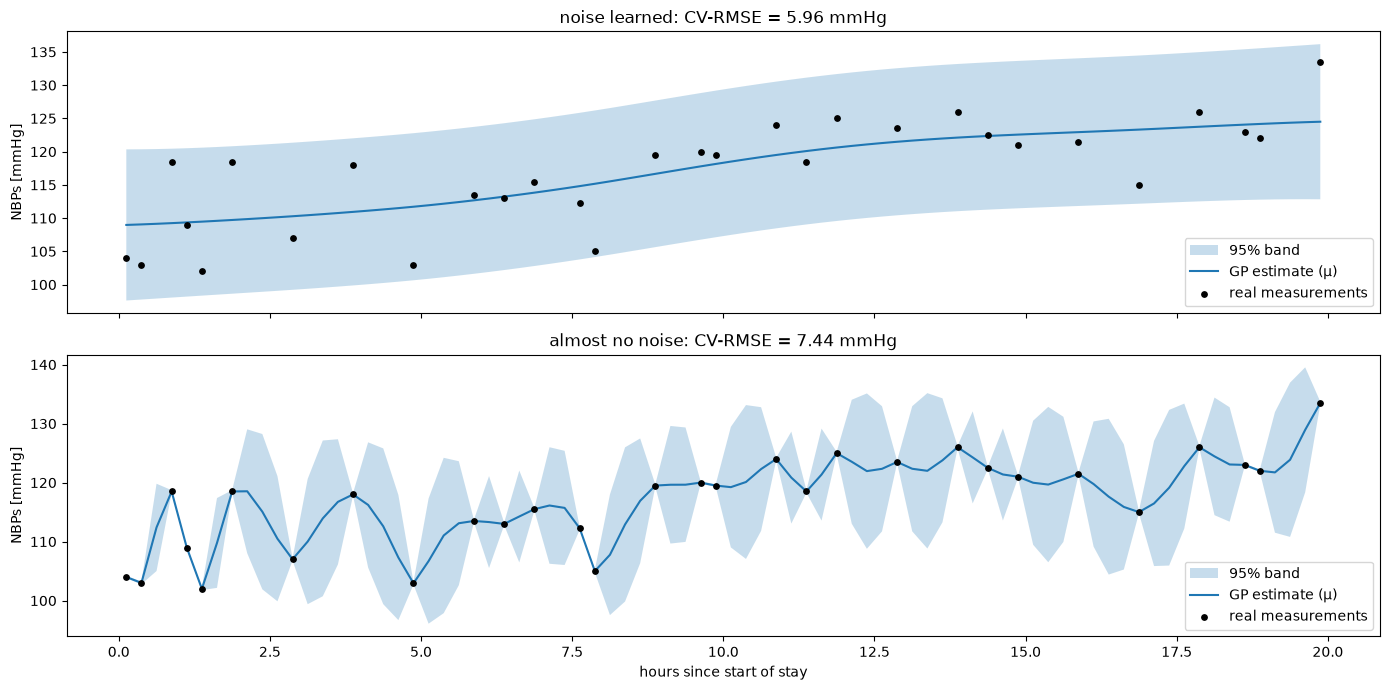

In [ ]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel as C, Matern, WhiteKernel
from sklearn.model_selection import KFold

# Data: p10019003, first 20 h, real systolic cuff values, 15-minute blocks
d = pd.read_csv(os.path.join(DATA_DIR, "p10019003_87033314n.csv.gz"),
                usecols=["time", "NBPs [mmHg]", "NBPd [mmHg]"])
cuff = d.dropna(subset=["NBPs [mmHg]"]).sort_values("time")
vals = cuff[["NBPs [mmHg]", "NBPd [mmHg]"]].fillna(-1)
real = cuff[vals.ne(vals.shift()).any(axis=1)].copy()
real["hours"] = (real["time"] - d["time"].min()) / TICKS_PER_SECOND / 3600
real = real[real["hours"] <= 20]

real["block"] = (real["hours"] // 0.25).astype(int)
obs = real.groupby("block")["NBPs [mmHg]"].mean()
X = ((obs.index.values + 0.5) * 0.25).reshape(-1, 1)   # block centre in hours
y = obs.values
X_all = (np.arange(80) * 0.25 + 0.125).reshape(-1, 1)

kernels = {
    "noise learned": C(1.0) * Matern(length_scale=1.0, nu=1.5) + WhiteKernel(noise_level=0.5),
    "almost no noise": C(1.0) * Matern(length_scale=1.0, nu=1.5)
                       + WhiteKernel(noise_level=1e-4, noise_level_bounds="fixed"),
}

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, (name, k) in zip(axes, kernels.items()):
    errors = []
    for tr, te in KFold(5, shuffle=True, random_state=42).split(X):
        gp = GaussianProcessRegressor(kernel=k, normalize_y=True, random_state=42).fit(X[tr], y[tr])
        errors.extend(gp.predict(X[te]) - y[te])
    rmse = np.sqrt(np.mean(np.square(errors)))

    gp = GaussianProcessRegressor(kernel=k, normalize_y=True, random_state=42).fit(X, y)
    mu, sigma = gp.predict(X_all, return_std=True)
    ax.fill_between(X_all.ravel(), mu - 1.96 * sigma, mu + 1.96 * sigma, alpha=0.25, label="95% band")
    ax.plot(X_all, mu, label="GP estimate (μ)")
    ax.scatter(X, y, color="black", s=15, zorder=3, label="real measurements")
    ax.set_title(f"{name}: CV-RMSE = {rmse:.2f} mmHg")
    ax.set_ylabel("NBPs [mmHg]")
    ax.legend(loc="lower right")
    print(f"{name:16s} CV-RMSE = {rmse:.2f} mmHg | learned kernel: {gp.kernel_}")

axes[-1].set_xlabel("hours since start of stay")
plt.tight_layout()
plt.show()

**Result:** the GP with learned noise predicts hidden measurements better (CV-RMSE 5.96 vs. 7.44 mmHg). Forcing the line through every point makes it overfit: it treats noise as real, fast changes. So the smooth line in section 12 is justified for filling gaps, but a real short dip cannot be told apart from noise; we therefore keep the original measurements (notebook 02).

3A (Grilla 15 min): Observaciones reales, bloques vacíos a imputar marcados en rojo, media predictiva GP y bandas de confianza  ± 1.96𝜎. Muestra que ofrece 4 pasos de alerta temprana (lead time) en la hora previa a una crisis.
3B (Grilla 30 min): Misma trayectoria con menor resolución temporal (solo 1 o 2 pasos previos a una crisis).